<a href="https://colab.research.google.com/github/dimplehasinipalla/machine-learning-sem5/blob/main/6_6_LOGISTICREGRESSION_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc

In [ ]:
np.random.seed(42)
n_patients = 100

# Creating predictors matching the DATAtab medical model
age = np.random.randint(20, 75, size=n_patients)
medication = np.random.choice([0, 1], size=n_patients, p=[0.5, 0.5])
weight = np.random.normal(70, 15, size=n_patients)

# Generate probability of having the disease
logit_z = -2.5 + (0.05 * age) - (1.2 * medication) + (0.03 * weight)
prob = 1 / (1 + np.exp(-logit_z))
disease = (prob > np.random.rand(n_patients)).astype(int)

# Create DataFrame
df = pd.DataFrame({
    'Disease': disease,
    'Age': age,
    'Medication': medication,
    'Weight': weight
})

print("Dataset successfully created!")

Dataset successfully created!


In [ ]:
# View the first 10 patients
df.head(10)

,Disease,Age,Medication,Weight
0,1,58,1,88.270757
1,0,71,1,64.158130
2,0,48,1,63.357965
3,0,34,0,75.673399
4,1,62,0,99.007597
5,1,27,0,71.214562
6,1,40,0,63.753155
7,1,58,0,82.862549
8,1,38,0,80.771924
9,0,42,0,55.727924


In [ ]:
# Fit Logistic Regression: Disease ~ Age + Medication + Weight
model = smf.logit("Disease ~ Age + Medication + Weight", data=df).fit()

# Print statistical summary (Coefficients, Std Error, z-value, p-value)
print(model.summary())

Optimization terminated successfully.
         Current function value: 0.519152
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:                Disease   No. Observations:                  100
Model:                          Logit   Df Residuals:                       96
Method:                           MLE   Df Model:                            3
Date:                Thu, 30 Jul 2026   Pseudo R-squ.:                  0.1245
Time:                        06:22:54   Log-Likelihood:                -51.915
converged:                       True   LL-Null:                       -59.295
Covariance Type:            nonrobust   LLR p-value:                  0.002033
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -4.0200      1.544     -2.604      0.009      -7.046      -0.994
Age            0.0360      0.

In [ ]:
# Calculate Odds Ratios and 95% Confidence Intervals
odds_ratios = np.exp(model.params)
conf = np.exp(model.conf_int())
conf.columns = ['Lower 2.5%', 'Upper 97.5%']

# Combine into a summary table
summary_df = pd.DataFrame({
    'Odds Ratio (OR)': odds_ratios,
    'Lower 2.5% CI': conf['Lower 2.5%'],
    'Upper 97.5% CI': conf['Upper 97.5%'],
    'p-value': model.pvalues
})

print("--- Odds Ratios & Confidence Intervals ---")
summary_df

--- Odds Ratios & Confidence Intervals ---


,Odds Ratio (OR),Lower 2.5% CI,Upper 97.5% CI,p-value
Intercept,0.017953,0.000871,0.370077,0.009219
Age,1.036640,1.003993,1.070347,0.027519
Medication,0.581699,0.225263,1.502125,0.262989
Weight,1.054792,1.020171,1.090588,0.001732


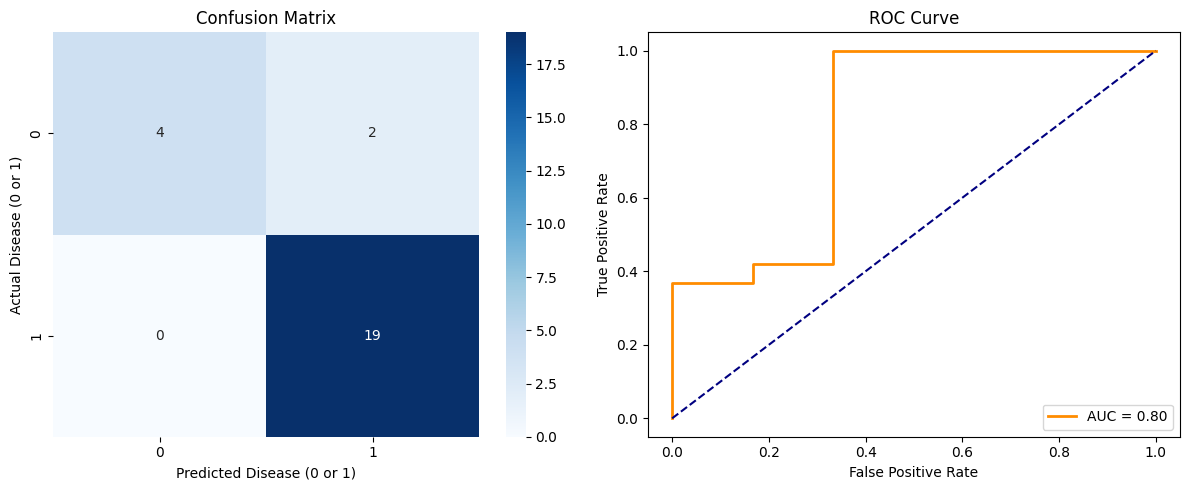

In [ ]:
# Prepare features and target
X = df[['Age', 'Medication', 'Weight']]
y = df['Disease']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# Train Scikit-Learn Classifier
clf = LogisticRegression()
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
y_prob = clf.predict_proba(X_test)[:, 1]

# Plotting
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Confusion Matrix
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', ax=ax[0])
ax[0].set_title('Confusion Matrix')
ax[0].set_xlabel('Predicted Disease (0 or 1)')
ax[0].set_ylabel('Actual Disease (0 or 1)')

# Plot 2: ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)
ax[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'AUC = {roc_auc:.2f}')
ax[1].plot([0, 1], [0, 1], color='navy', linestyle='--')
ax[1].set_xlabel('False Positive Rate')
ax[1].set_ylabel('True Positive Rate')
ax[1].set_title('ROC Curve')
ax[1].legend(loc="lower right")

plt.tight_layout()
plt.show()